# Lecture 10 – Storing and querying data: DuckDB and SQL

QSS 20 · Modern Statistical Computing · Fall 2026

### Agenda

- Why databases and SQL.
- Tables, schemas, and keys.
- DuckDB: one database file from saved files and DataFrames.
- SQL clause by clause: `SELECT`, `WHERE`, `GROUP BY`, `HAVING`, `ORDER BY`.
- Missing values: `NULL`.
- `CASE`, `WITH`, and joins.
- SQL and pandas side by side.

## Where we left off

- Lecture 8: the city's API gave the 3,469 crashes that killed someone in New
  York since July 2012.
- Lecture 9: Wikipedia gave US deaths and population by year, and the 2020
  population of each borough.

### Setup: install once

This lecture adds one package: `python-duckdb`, a database that runs inside
Python. Its import name is `duckdb`. Install it once, in a terminal, not in
this notebook:

```bash
conda activate qss20
conda install python-duckdb
```

- `conda activate qss20` makes the course environment the active one, so
  `conda install` puts the packages there. Type `y` when conda asks to
  proceed.
- If an import in the next cell still fails, restart the kernel
  (Kernel → Restart Kernel) and run it again.

### Setup: imports and folders

Load every package the lecture uses, and name the two data folders.

In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_rows', 16)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'
# Show only the last line of an error message.
%xmode Minimal

RAW = Path('../../data/raw')
DERIVED = Path('../../data/derived')

Exception reporting mode: Minimal


- Every import sits in this one cell. `json` and `pathlib` come with Python.

## Why learn databases and SQL?

### You already sent a query in lecture 8

- The city's crash table holds 2,269,187 police-reported crashes since July
  2012. You did not download it. You sent conditions, and the city's server
  sent back only the 3,469 fatal crashes:

```python
params = {'$where': 'number_of_persons_killed > 0',
          '$order': 'collision_id',
          '$limit': 1000, '$offset': offset}
```

- `$where`, `$select`, `$group`, `$order`, and `$limit` belong to SoQL, a
  version of SQL. The city keeps its crash records in a database, and that
  database ran your conditions on the city's computer.

### The data keep changing

- The [crash dataset page](https://data.cityofnewyork.us/d/h9gi-nx95) lists
  its update frequency as daily: new crashes arrive as police file reports.
  (A note on the page says that the automatic update is paused while the city
  repairs it.)
- Old rows change too. The page calls the data preliminary: a record changes
  when police amend a crash report with revised details.
- A file you save is a copy of the table on one day. A database keeps one
  current table, and each query reads the rows as they are when it runs.

### One file instead of many files and versions

<img src="images/files-vs-database.png" width="640" alt="Two file windows. Left, titled 28 files behind five tables: a data folder with fatal-crashes-page-1 to 4, persons-killed-page-1 to 4, and fatal-crash-vehicles-batch-1 to 18 as JSON files, plus us_traffic_deaths.csv and nyc_boroughs.csv. Below them, marked as examples, the copies an analysis tends to add: crashes_clean.csv, crashes_clean_v2.csv, crashes_clean_FINAL.csv, persons_with_crashes.csv. A note says every value is text and each reader converts the types again. Right, titled One database file: traffic.duckdb with five tables and their row counts, crashes 3,469, persons 3,636, vehicles 5,961, us_deaths 127, boroughs 5, and the stored column types of crashes, such as collision_id INTEGER and crash_date DATE. A note says a cleaned table is a query rerun from the raw rows, not a new file.">

- Lectures 8 and 9 left 28 files behind five tables. A cleaning step can add
  another copy, such as `crashes_clean_v2.csv`.
- A database file holds every table, with each column's name and type. A CSV
  file stores no types, so every program that reads it guesses them again.
- A cleaned table is a query that you rerun on the raw rows, not another file.

### A bank keeps its accounts in a database

- Every card payment, deposit, and transfer changes a balance. Many programs
  send these changes to the bank's tables at the same moment.
- A transfer of 200 dollars from Ana to Ben is two changes: subtract 200 from
  Ana's balance, then add 200 to Ben's. If the program stops between the two,
  the 200 dollars disappear.
- A database groups the two changes into one **transaction**: both happen, or
  neither does. It also controls who may read or change each table.
- A CSV file does neither. Two programs that write the same file at the same
  time can overwrite each other's changes.

### Why not read every file into pandas?

- So far, pandas read each file whole into memory. That works for a table of
  moderate size that does not change.
- A query reads only the rows and columns it needs, so a table can be larger
  than your computer's memory.

### SQL works across database systems

- **SQL** (Structured Query Language) is a language for asking a database
  for a table. A query takes tables in and returns a table.
- Most organizations keep their data in a **database management system**
  (DBMS): PostgreSQL, MySQL, SQLite, BigQuery, Snowflake, and others. All of
  them accept SQL, with small differences between them.
- In Stack Overflow's
  [2025 Developer Survey](https://survey.stackoverflow.co/2025/technology),
  58.6 percent of the 31,771 respondents who answered had done extensive work
  in SQL over the past year, slightly more than in Python (57.9 percent). Only
  JavaScript and HTML/CSS ranked higher. The survey asks developers in
  general, not only data scientists.

### Servers and embedded databases

- Most databases run as a **server**: PostgreSQL and MySQL wait on another
  computer, and you connect over the network with a login, often through a
  VPN. Keep logins in `.env`, as with API keys, never in a notebook.
- **DuckDB** and SQLite are **embedded**: the database is one file on your own
  computer, and the engine runs inside Python. DuckDB needs no server and no
  password, and it reads CSV, JSON, and pandas DataFrames.
- Documentation: [DuckDB's Python client](https://duckdb.org/docs/stable/clients/python/overview)
  and [DuckDB's SQL introduction](https://duckdb.org/docs/stable/sql/introduction).

### Tables, rows, and columns

- A **table** (or **relation**) holds rows (**records**) and columns
  (**fields**).
- Its **schema** lists each column's name and type, such as text, a whole
  number, or a date. Every value in a column has that column's type.
- Rows have no labels and no order. When order matters, ask for it with
  `ORDER BY`.
- A **relational database** stores several tables that refer to each other
  through keys. The crash database has five.

## Build the crash database

- Our saved files are a copy of the city's tables, so this lecture reads and
  summarizes rows and does not change them.
- The city publishes three related tables:
  [crashes](https://data.cityofnewyork.us/d/h9gi-nx95),
  [persons](https://data.cityofnewyork.us/d/f55k-p6yu) killed, and
  [vehicles](https://data.cityofnewyork.us/d/bm4k-52h4) involved. With the two
  tables from lecture 9, that makes five tables.

### Keys link the tables

- A **primary key** identifies one row: `collision_id` identifies a crash in
  `crashes`.
- In `persons`, `collision_id` is a **foreign key**: it holds another table's
  key, and it links each person to a crash. Several people can share one
  crash's key.

![Five tables. crashes, one row per fatal crash, has the key collision_id. persons, one row per person killed, and vehicles, one row per vehicle in a fatal crash, each hold a collision_id that links many rows to one crash. us_deaths, one row per year, links to crashes through the year of crash_date. boroughs, one row per borough, links to crashes through the borough name, after the names are cleaned: BROOKLYN against Brooklyn](images/traffic-schema.png)

### Open a database file

Store the five tables in one file, so that a later notebook can open them
without reading the saved pages again.

In [2]:
con = duckdb.connect(str(DERIVED / 'traffic.duckdb'))

- With a path, `duckdb.connect(path)` opens that database file, and creates it
  if it does not exist. Tables in the file stay after the notebook stops.
- `con`, the **connection**, sends every statement and query to that database.
- `duckdb.connect()` with no path opens an empty database in memory, which
  disappears when the notebook stops. The activity uses one.

### Rebuild lecture 8's crash DataFrame

Read the saved crash pages into one pandas DataFrame, as in lecture 8.

In [3]:
pages = sorted((RAW / 'nyc').glob('fatal-crashes-page-*.json'))
crashes_df = pd.DataFrame([
    row for p in pages
    for row in json.loads(p.read_text(encoding='utf-8'))
])

- This cell repeats lecture 8's code. `crashes_df` is a pandas DataFrame in
  Python's memory, not a table in the database.
- DuckDB finds a DataFrame by its Python name, so a query can say
  `FROM crashes_df` and read it as if it were a table.

### The order of clauses

```sql
SELECT   <columns>
FROM     <table>
WHERE    <condition on rows>
GROUP BY <columns>
HAVING   <condition on groups>
ORDER BY <columns>
LIMIT    <number of rows>;
```

- Only `SELECT` and `FROM` are required. The clauses must come in this order.
- By convention, keywords are in capitals, and each clause starts a line.
- SQL is **declarative**: you state the result you need, and the database
  decides how to compute it.

### `SELECT ... FROM`: ask for columns of a table

Ask for three columns of the crash DataFrame.

In [4]:
con.sql('''
SELECT collision_id, crash_date, borough
FROM crashes_df
''').df()

,collision_id,crash_date,borough
0,516,2012-08-23T00:00:00.000,MANHATTAN
1,1303,2012-11-26T00:00:00.000,None
2,3610,2013-08-21T00:00:00.000,MANHATTAN
3,4421,2013-11-22T00:00:00.000,MANHATTAN
4,6184,2012-11-06T00:00:00.000,MANHATTAN
...,...,...,...
3464,4896315,2026-05-03T00:00:00.000,None
3465,4896548,2026-05-04T00:00:00.000,None
3466,4896552,2026-05-03T00:00:00.000,None
3467,4896677,2026-05-01T00:00:00.000,None


- A first query. `SELECT` names the columns, and `FROM` names the table.
- `con.sql(query)` runs a query and returns a **relation**, a result still
  inside DuckDB. `.df()` pulls it into Python as a pandas DataFrame.
- 3,469 rows, one per crash. pandas shows the first five and the last five.

### `*` and `LIMIT`: every column, three rows

In [5]:
con.sql('SELECT * FROM crashes_df LIMIT 3').df()

,collision_id,crash_date,crash_time,borough,zip_code,on_street_name,number_of_persons_injured,number_of_persons_killed,number_of_pedestrians_killed,number_of_cyclist_killed,number_of_motorist_killed,contributing_factor_vehicle_1,vehicle_type_code1,latitude,longitude,cross_street_name
0,516,2012-08-23T00:00:00.000,13:22,MANHATTAN,10004,BROAD STREET,3,1,1,0,0,Driver Inattention/Distraction,SPORT UTILITY / STATION WAGON,40.7049500,-74.0115487,None
1,1303,2012-11-26T00:00:00.000,8:12,None,None,None,0,1,1,0,0,Unspecified,SPORT UTILITY / STATION WAGON,None,None,PARKING GARAGE @ 21 BARCLAY STREET
2,3610,2013-08-21T00:00:00.000,17:25,MANHATTAN,10012,WEST HOUSTON STREET,0,1,0,0,1,Physical Disability,MOTORCYCLE,40.7269334,-73.9999170,None


- `*` means every column. `LIMIT 3` keeps three rows, like `.head(3)`.
  Without an order, they are whichever rows the database reaches first.

### `DESCRIBE`: list each column's type

In [6]:
con.sql('DESCRIBE crashes_df').df()[['column_name', 'column_type']]

,column_name,column_type
0,collision_id,VARCHAR
1,crash_date,VARCHAR
2,crash_time,VARCHAR
3,borough,VARCHAR
4,zip_code,VARCHAR
5,on_street_name,VARCHAR
6,number_of_persons_injured,VARCHAR
7,number_of_persons_killed,VARCHAR
8,number_of_pedestrians_killed,VARCHAR
9,number_of_cyclist_killed,VARCHAR


- All 16 columns are `VARCHAR`, text, because the API sent every value as
  text.

### `ORDER BY`: sort the crashes by `collision_id`

Find the three largest crash IDs.

In [7]:
con.sql('''
SELECT collision_id
FROM crashes_df
ORDER BY collision_id DESC
LIMIT 3
''').df()

,collision_id
0,999636
1,999633
2,998430


- `ORDER BY` sorts; `DESC` puts the largest first, and `ASC`, the default,
  the smallest.
- These are not the largest IDs. Text sorts character by character, so
  `'999636'` comes after `'4900083'`, because `'9'` comes after `'4'`.

### `CAST`: convert text to numbers and dates

Convert three columns to their proper types, give each a short name, and sort
again.

In [8]:
con.sql('''
SELECT CAST(collision_id AS INTEGER)              AS collision_id,
       CAST(crash_date AS DATE)                   AS crash_date,
       CAST(number_of_persons_killed AS INTEGER)  AS killed
FROM crashes_df
ORDER BY collision_id DESC
LIMIT 3
''').df()

,collision_id,crash_date,killed
0,4900083,2025-07-28,1
1,4896677,2026-05-01,1
2,4896552,2026-05-03,1


- `CAST(x AS INTEGER)` converts a column's type, like `.astype(int)` in pandas.
  The largest ID is 4,900,083; 2,984 crashes have an ID above 999,636.
- `AS` names an output column. `CAST` works row by row: one value in, one
  value out.

### `CREATE TABLE ... AS`: store the typed crash table

Store the typed columns in the database file, with a cleaned street name and
the number of pedestrians killed.

In [9]:
con.execute('''
CREATE OR REPLACE TABLE crashes AS
SELECT CAST(collision_id AS INTEGER)               AS collision_id,
       CAST(crash_date AS DATE)                    AS crash_date,
       borough,
       TRIM(on_street_name)                        AS street,
       CAST(number_of_persons_killed AS INTEGER)   AS killed,
       CAST(number_of_pedestrians_killed AS INTEGER) AS pedestrians_killed
FROM crashes_df
''');

- `CREATE TABLE name AS SELECT ...` stores the result of a query as a new
  table in the database file. Its columns and types come from the `SELECT`.
- `con.execute` runs a statement that changes the database, such as
  `CREATE TABLE`. `con.sql` runs a query and returns a table to look at.
- `CREATE OR REPLACE` rebuilds the table when you rerun the cell, instead of
  failing because the table exists.
- `TRIM` removes spaces at both ends of a text value, like `.str.strip()`.
  1,883 street names in the city's records have such spaces.

In [10]:
con.sql('DESCRIBE crashes').df()[['column_name', 'column_type']]

,column_name,column_type
0,collision_id,INTEGER
1,crash_date,DATE
2,borough,VARCHAR
3,street,VARCHAR
4,killed,INTEGER
5,pedestrians_killed,INTEGER


- The stored table now has `INTEGER` and `DATE` columns.

### `read_json_auto`: read the person pages directly

Create the persons table straight from the saved JSON pages, without pandas.

In [11]:
con.execute(f'''
CREATE OR REPLACE TABLE persons AS
SELECT unique_id,
       CAST(collision_id AS INTEGER) AS collision_id,
       CAST(crash_date AS DATE)      AS crash_date,
       person_type,
       CAST(person_age AS INTEGER)   AS age,
       person_sex
FROM read_json_auto('{RAW}/nyc/persons-killed-page-*.json')
''');

- `read_json_auto` reads JSON files and guesses each column's type. The `*`
  in the file name reads every page at once, as `glob` did.
- The query is an f-string, so Python puts the folder path in place of
  `{RAW}` before DuckDB reads the query.
- `persons` has one row per person killed. Its `collision_id` links each
  person to a crash.

### Load the vehicles and the two Wikipedia tables

Load the other three tables the same way: the vehicles from JSON, and lecture
9's two tables from CSV.

In [12]:
con.execute(f'''
CREATE OR REPLACE TABLE vehicles AS
SELECT unique_id,
       CAST(collision_id AS INTEGER) AS collision_id,
       vehicle_type
FROM read_json_auto('{RAW}/nyc/fatal-crash-vehicles-batch-*.json')
''')

In [13]:
con.sql('''
SELECT * FROM vehicles
''').df()

,unique_id,collision_id,vehicle_type
0,8392168,516,SPORT UTILITY / STATION WAGON
1,8393741,1303,PASSENGER VEHICLE
2,8393740,1303,SPORT UTILITY / STATION WAGON
3,8398329,3610,VAN
4,8398328,3610,MOTORCYCLE
...,...,...,...
5956,19598178,4227325,Bike
5957,19666242,4231393,None
5958,19145359,4231424,Taxi
5959,19641565,4232251,Bus


In [14]:
con.execute(f'''
CREATE OR REPLACE TABLE us_deaths AS
SELECT * FROM read_csv_auto('{DERIVED}/us_traffic_deaths.csv');
CREATE OR REPLACE TABLE boroughs AS
SELECT * FROM read_csv_auto('{DERIVED}/nyc_boroughs.csv');
''')

In [15]:
con.sql('''
SELECT * FROM us_deaths
''').df()

,year,deaths,population,per_100k,estimate
0,1899,26,NaN,NaN,False
1,1900,36,76094000.0,0.05,False
2,1901,54,77584000.0,0.07,False
3,1902,79,79163000.0,0.10,False
4,1903,117,80632000.0,0.15,False
...,...,...,...,...,...
122,2021,43230,332915073.0,13.02,False
123,2022,42514,338289857.0,12.76,False
124,2023,40990,339996563.0,12.06,False
125,2024,42789,NaN,NaN,False


In [16]:
con.sql('''
SELECT * FROM boroughs
''').df()

,borough,county,population
0,The Bronx,Bronx,1472654
1,Brooklyn,Kings,2736074
2,Manhattan,New York,1694251
3,Queens,Queens,2405464
4,Staten Island,Richmond,495747


- `read_csv_auto` does for CSV files what `read_json_auto` does for JSON.
- A semicolon ends one statement, so one `execute` can run two.
- `vehicles` lists the vehicles in the 3,469 fatal crashes.

### Count the rows in every table

List the tables in the file, then count the rows in each one.

In [17]:
con.sql('SHOW TABLES').df()

,name
0,boroughs
1,crashes
2,persons
3,us_deaths
4,vehicles


In [18]:
{t: con.sql(f'SELECT COUNT(*) FROM {t}').fetchone()[0]
 for t in ['crashes', 'persons', 'vehicles', 'us_deaths', 'boroughs']}

{'crashes': 3469,
 'persons': 3636,
 'vehicles': 5961,
 'us_deaths': 127,
 'boroughs': 5}

- `SHOW TABLES` lists the tables in the database. `COUNT(*)` counts rows, and
  `.fetchone()[0]` returns the first value of the first row, here one count.
- 3,469 crashes, as in lecture 8; 127 years and 5 boroughs, as in lecture 9.
  3,636 persons killed, more than the 3,617 deaths the crash table counts.
  The joins below find the difference.

<div class="alert alert-info">

**Key idea.** For every table, write down what one row is and which column
identifies it. Count the rows after every load and every join.

</div>

### Close and reopen the file

Close the connection, open the file again, and list its tables.

In [19]:
con.close()
con = duckdb.connect(str(DERIVED / 'traffic.duckdb'))
con.sql('SHOW TABLES').df()

,name
0,boroughs
1,crashes
2,persons
3,us_deaths
4,vehicles


- The five stored tables are still in the file.
- `crashes_df` is not in the file. It lives in Python's memory, not in the
  database.

## SQL clause by clause

### `ORDER BY` a number: the deadliest crashes

List the five crashes that killed the most people.

In [20]:
con.sql('''
SELECT crash_date, borough, street, killed
FROM crashes
ORDER BY killed DESC
LIMIT 5
''').df()

,crash_date,borough,street,killed
0,2017-10-31,MANHATTAN,WEST STREET,8
1,2012-07-22,QUEENS,94 AVENUE,5
2,2024-01-01,None,CROSS ISLAND PARKWAY,5
3,2017-09-18,QUEENS,NORTHERN BOULEVARD,4
4,2020-01-25,None,GRAND CENTRAL PKWY,4


- `killed` is an integer now, so the sort is by number.
- The deadliest record, 8 people on West Street on 31 October 2017, was an
  attack: a driver steered a truck onto a bike path. Police reports record
  each death in a crash, whatever its cause.

### `WHERE`: keep the rows that meet a condition

List Brooklyn crashes that killed at least one pedestrian.

In [21]:
con.sql('''
SELECT crash_date, street, pedestrians_killed
FROM crashes
WHERE borough = 'BROOKLYN' AND pedestrians_killed > 0
LIMIT 5
''').df()

,crash_date,street,pedestrians_killed
0,2014-02-03,OCEANA TERRACE,1
1,2012-12-18,OCEAN PARKWAY,1
2,2013-03-23,OCEAN AVENUE,1
3,2013-07-27,NOSTRAND AVENUE,1
4,2012-12-08,QUENTIN ROAD,1


- `WHERE` keeps the rows where the condition is true.
- SQL tests equality with one `=`, not pandas's `==`. Combine conditions with
  `AND`, `OR`, and `NOT`; test a list with `borough IN ('BRONX', 'QUEENS')`.

In pandas, text can go in single or double quotes. Write the same filter with
double quotes:

In [29]:
con.sql('''
SELECT COUNT(*) 
FROM crashes 
WHERE borough = "BROOKLYN"
''').df()

BinderException: Binder Error: Referenced column "BROOKLYN" not found in FROM clause!
Candidate bindings: "borough"

- Text goes in **single** quotes: `'BROOKLYN'`. Double quotes name a column,
  so DuckDB looks for a column called `BROOKLYN` and stops.

### `COUNT` and `SUM`: one row from many rows

Count the Brooklyn crashes that killed a pedestrian, and add up the
pedestrians they killed.

In [30]:
con.sql('''
SELECT COUNT(*) AS crashes, SUM(pedestrians_killed) AS pedestrians
FROM crashes
WHERE borough = 'BROOKLYN' AND pedestrians_killed > 0
''').df()

,crashes,pedestrians
0,401,406.0


- `COUNT(*)` counts rows and `SUM` adds a column, over the rows that `WHERE`
  kept: 401 crashes killed 406 pedestrians.
- These are **aggregate functions**: many rows in, one value out. `AVG`,
  `MIN`, and `MAX` work the same way.

### `LIKE`: match a pattern in text

List the crashes on streets whose names start with `QUEENS B`.

In [31]:
con.sql('''
SELECT street
FROM crashes
WHERE street LIKE 'QUEENS B%'
''').df()

,street
0,QUEENS BOULEVARD
1,QUEENS BOULEVARD
2,QUEENS BOULEVARD
3,QUEENS BOULEVARD
4,QUEENS BOULEVARD
...,...
15,QUEENS BOULEVARD
16,QUEENS BOULEVARD
17,QUEENS BOULEVARD
18,QUEENS BOULEVARD


- In `LIKE`, `%` stands for any characters, and `_` for exactly one.
- `LIKE` is case-sensitive: `'queens b%'` matches no row here. `ILIKE`
  ignores capital letters.
- 20 rows, one per crash, so most names repeat.

### `DISTINCT`: drop repeated rows

Keep one copy of each street name that matches the pattern.

In [32]:
con.sql('''
SELECT DISTINCT street
FROM crashes
WHERE street LIKE 'QUEENS B%'
''').df()

,street
0,QUEENS BLVD
1,QUEENS BOULEVARD


- `DISTINCT` keeps one copy of each different row.
- One street, two spellings. A filter on `'QUEENS BOULEVARD'` alone would miss
  every crash recorded as `'QUEENS BLVD'`. Lecture 11 cleans text like this.

### ❓ Question

```sql
SELECT COUNT(*), COUNT(borough), COUNT(street)
FROM crashes
```

The table has 3,469 rows. Are the three counts equal?

<details><summary>Answer</summary>

**No: 3,469, 2,101, and 3,163.** `COUNT(*)` counts rows. `COUNT(column)` counts
the rows where that column has a value. 1,368 crashes have no borough and 306
have no street.

</details>

### `NULL`: a missing value

Count all rows, then the rows that record a borough and a street.

In [33]:
con.sql('''
SELECT COUNT(*), COUNT(borough), COUNT(street)
FROM crashes
''').df()

,count_star(),count(borough),count(street)
0,3469,2101,3163


Count the crashes with no borough. Try `= NULL` first.

In [34]:
con.sql('SELECT COUNT(*) FROM crashes WHERE borough = NULL').df()

,count_star()
0,0


Now try `IS NULL`.

In [35]:
con.sql('SELECT COUNT(*) FROM crashes WHERE borough IS NULL').df()

,count_star()
0,1368


- `NULL` is SQL's missing value, like `NaN`. Any comparison with `NULL`,
  even `NULL = NULL`, is unknown rather than true, so `WHERE borough = NULL`
  keeps no rows. Test for it with `IS NULL` or `IS NOT NULL`.

### `GROUP BY`: one row per group

Count the fatal crashes and the deaths in each borough.

In [36]:
con.sql('''
SELECT borough, COUNT(*) AS fatal_crashes, SUM(killed) AS killed
FROM crashes
GROUP BY borough
ORDER BY fatal_crashes DESC
''').df()

,borough,fatal_crashes,killed
0,None,1368,1441.0
1,BROOKLYN,721,740.0
2,QUEENS,576,607.0
3,MANHATTAN,382,396.0
4,BRONX,318,325.0
5,STATEN ISLAND,104,108.0


- `GROUP BY borough` makes one output row per borough, like `groupby`. Every
  column in `SELECT` must be a grouping column or an aggregate function.
- `NULL` forms its own group, and it is the largest: **1,368** of 3,469 fatal
  crashes, 39 percent, have no borough. A ranking of boroughs from this table
  would compare only the crashes that happen to record one.

### `HAVING`: keep the groups that meet a condition

Keep only the boroughs with at least 500 fatal crashes. `WHERE` keeps rows, so
try it first.

In [37]:
con.sql('''
SELECT borough, COUNT(*) AS fatal_crashes
FROM crashes
WHERE COUNT(*) >= 500
GROUP BY borough
''')

BinderException: Binder Error: WHERE clause cannot contain aggregates!

- `WHERE` runs before the rows form groups, so no count exists yet.

In [38]:
con.sql('''
SELECT borough, COUNT(*) AS fatal_crashes
FROM crashes
GROUP BY borough
HAVING COUNT(*) >= 500
ORDER BY fatal_crashes DESC
''').df()

,borough,fatal_crashes
0,None,1368
1,BROOKLYN,721
2,QUEENS,576


- `HAVING` filters **groups** after counting; `WHERE` filters **rows** before
  grouping. Brooklyn and Queens remain, and so does the `NULL` group.

### The order of clauses

```sql
SELECT   <columns>
FROM     <table>
WHERE    <condition on rows>
GROUP BY <columns>
HAVING   <condition on groups>
ORDER BY <columns>
LIMIT    <number of rows>;
```

- Only `SELECT` and `FROM` are required. The clauses must come in this order.
- By convention, keywords are in capitals, and each clause starts a line.
- SQL is **declarative**: you state the result you need, and the database
  decides how to compute it.

<div class="alert alert-info">

**Key idea.** You write `SELECT` first, but a query runs in this order:
`FROM`, `WHERE`, `GROUP BY`, `HAVING`, `SELECT`, `ORDER BY`, `LIMIT`. Filter
rows with `WHERE`, groups with `HAVING`, and count the `NULL`s before you
group.

</div>

- `ORDER BY fatal_crashes` can use a name made in `SELECT`, because it runs
  later. `WHERE` runs first, so it cannot. DuckDB also lets `GROUP BY` use
  such a name; some databases do not.

<div class="alert alert-success">

### Activity 1 · What does this query return?

```sql
SELECT street, COUNT(*) AS fatal_crashes
FROM crashes
GROUP BY street
HAVING COUNT(*) >= 25
ORDER BY fatal_crashes DESC
```

Before you run it, write down:

1. What is one row of the result, and how many columns does it have?
2. Can a street appear in two rows?
3. Which clause decides which streets remain, and why is it not `WHERE`?
4. Will the crashes with no street appear in the result?

Then run it below.

</div>

### Streets with 25 or more fatal crashes

Run the query from Activity 1.

In [39]:
con.sql('''
SELECT street, COUNT(*) AS fatal_crashes
FROM crashes
GROUP BY street
HAVING COUNT(*) >= 25
ORDER BY fatal_crashes DESC
''').df()

,street,fatal_crashes
0,None,306
1,BELT PARKWAY,54
2,BROADWAY,47
3,ATLANTIC AVENUE,43
4,3 AVENUE,39
5,MAJOR DEEGAN EXPRESSWAY,35
6,GRAND CENTRAL PKWY,33
7,LINDEN BOULEVARD,30
8,HENRY HUDSON PARKWAY,28
9,BRUCKNER BOULEVARD,27


- One row per street, two columns. `GROUP BY street` makes each street one
  group, so no street appears twice (as stored: spellings still differ).
- `HAVING` keeps the streets with at least 25 crashes. `WHERE` cannot, because
  it runs before the count exists.
- The 306 crashes with no street form one `NULL` group, the largest of all.
  Highways such as the Belt Parkway and the Major Deegan Expressway rank next
  to city streets such as Broadway and Atlantic Avenue.

## Who dies: `AVG`, `MEDIAN`, and `CASE`

- The crash table counts deaths. The persons table says who died: a
  pedestrian, a cyclist, or a person in a vehicle, with age and sex.

> **Who are the people that New York's crashes kill?**

For each type of person, count the people killed and summarize their ages.

In [40]:
con.sql('''
SELECT person_type, COUNT(*) AS killed,
       MEDIAN(age) AS median_age, ROUND(AVG(age), 1) AS mean_age,
       MAX(age) AS max_age
FROM persons
GROUP BY person_type
ORDER BY killed DESC
''').df()

,person_type,killed,median_age,mean_age,max_age
0,Pedestrian,1805,58.0,53.4,149
1,Occupant,1466,33.0,38.6,124
2,Bicyclist,294,39.5,42.0,91
3,Other Motorized,71,43.0,42.8,74


- Pedestrians are half of the people killed: **1,805** of 3,636. Their median
  age is **58**; people killed inside vehicles have a median age of 33.
- `MEDIAN` and `AVG` are aggregate functions, like `COUNT`. `ROUND(x, 1)`
  keeps one decimal place.
- Categories such as "Other Motorized" are the city's own. Read the data
  dictionary on the dataset's page before you interpret one.

### ❓ Question

One record gives an age of 149, and another gives 124. Which summary do
those two errors move more, `AVG(age)` or `MEDIAN(age)`?

<details><summary>Answer</summary>

**`AVG`.** The mean adds every value, so an impossible age pulls it up. The
median is the middle value; one or two extreme values barely move it. With
data entry errors you cannot fix, report the median, and report the errors.

</details>

### `CASE`: a new column from conditions

Put each pedestrian killed into an age group, then count each group.

In [41]:
con.sql('''
SELECT CASE WHEN age < 18 THEN 'under 18'
            WHEN age < 65 THEN '18 to 64'
            WHEN age >= 65 THEN '65 and older'
            ELSE 'age not recorded'
       END AS age_group,
       COUNT(*) AS pedestrians_killed
FROM persons
WHERE person_type = 'Pedestrian'
GROUP BY age_group
ORDER BY pedestrians_killed DESC
''').df()

,age_group,pedestrians_killed
0,18 to 64,982
1,65 and older,662
2,under 18,140
3,age not recorded,21


- `CASE WHEN ... THEN ... ELSE ... END` checks the conditions in order and
  returns the value of the first one that holds, like `if`/`elif`/`else`.
- A missing age fails every comparison, so it falls to `ELSE`. Without the
  `ELSE`, the result would be `NULL`.
- **662** of the 1,805 pedestrians killed, 37 percent, were 65 or older. 21
  have no recorded age.

## People per crash: `COUNT(DISTINCT ...)` and `WITH`

A crash that kills three people is one row in `crashes` and three rows in
`persons`. Before joining the two tables, count how often that happens.

Count the rows of `persons` and the different crashes they belong to.

In [42]:
con.sql('''
SELECT COUNT(*) AS persons, COUNT(DISTINCT collision_id) AS crashes
FROM persons
''').df()

,persons,crashes
0,3636,3486


- `COUNT(DISTINCT column)` counts the different values in a column.
- 3,636 people died in 3,486 crashes, so some crashes killed more than one
  person. `collision_id` repeats in `persons`, as a foreign key can.

### `WITH`: name a step, then query it

Count the people killed in each crash, then count the crashes by that number.

In [43]:
con.sql('''
WITH per_crash AS (
    SELECT collision_id, COUNT(*) AS people_killed
    FROM persons
    GROUP BY collision_id
)
SELECT people_killed, COUNT(*) AS crashes
FROM per_crash
GROUP BY people_killed
ORDER BY people_killed
''').df()

,people_killed,crashes
0,1,3371
1,2,93
2,3,15
3,4,4
4,5,2
5,8,1


- `WITH per_crash AS (...)` gives the first query's result a name. In
  `per_crash`, one row is one crash. The second query reads `per_crash` like
  a table.
- The name exists only while this query runs. Each step can be read, and
  checked, on its own.
- 3,371 crashes killed one person, and 115 killed two or more.

## Joins

- `JOIN` matches rows of two tables on a key, like `merge` in lecture 7.
- `INNER JOIN` keeps matches only; `LEFT JOIN` keeps every row of the first
  table, with `NULL` where nothing matches; `RIGHT` and `FULL` follow the same
  rules as `how='right'` and `how='outer'`. A plain `JOIN` is an inner join.
- `ON p.collision_id = c.collision_id` states the match. `FROM persons AS p`
  gives the table a short name, so `p.collision_id` says which table's column
  you mean.

### ❓ Question

```sql
SELECT COUNT(*) AS persons, COUNT(c.collision_id) AS matched
FROM persons AS p
LEFT JOIN crashes AS c ON p.collision_id = c.collision_id
```

`persons` has 3,636 rows, and each crash appears once in `crashes`. How many
rows does the join return, and will every person find a crash?

<details><summary>Answer</summary>

**3,636 rows; 3,608 match.** Each person matches at most one crash, so the
left join keeps one row per person. 28 people killed have no crash in the
saved crash table.

</details>

### `LEFT JOIN`: match each person to a crash

Join every person to their crash, and count the people who find one.

In [44]:
con.sql('''
SELECT COUNT(*) AS persons, COUNT(c.collision_id) AS matched
FROM persons AS p
LEFT JOIN crashes AS c ON p.collision_id = c.collision_id
''').df()

,persons,matched
0,3636,3608


### `USING`: the same join, written shorter

List the unmatched people by year of death. Both tables call the key
`collision_id`, so `USING (collision_id)` states the match.

In [45]:
con.sql('''
SELECT year(p.crash_date) AS year, COUNT(*) AS unmatched
FROM persons AS p
LEFT JOIN crashes AS c USING (collision_id)
WHERE c.collision_id IS NULL
GROUP BY year
ORDER BY year
''').df()

,year,unmatched
0,2016,1
1,2017,5
2,2018,1
3,2026,21


- `USING (collision_id)` matches on a column with the same name in both
  tables, and keeps one copy of it.
- `year(date)` takes the year out of a date. `WHERE c.collision_id IS NULL`
  keeps the people whose crash did not match.

- 21 of the 28 died in May or June 2026. The saved crash file ends on 4 May
  2026, and the persons file on 9 June 2026. The other 7 belong to crashes
  that the crash table does not count as deadly.
- Two tables from the same city disagree. Count the matches after each join
  to find where.

## Stopping point

- If class time is short, open `lec10_activity.ipynb` now. The activity uses
  nothing after this slide.
- The rate comparison below is a second question for later reading.

## New York and the nation: rates

- New York had 297 deaths in both 2013 and 2021, and US deaths rose 31
  percent. Those are counts. The nation's population grew over those years,
  and the city holds about one American in 38.

> **Did New York City's traffic death rate fall relative to the nation's after
> 2013?**

- A rate needs two tables joined by year: deaths from `crashes`, and
  population from `us_deaths` and `boroughs`.

### Count New York's deaths by year, then join the US table

Name the yearly New York counts with `WITH`, then join them to `us_deaths` by
year.

In [46]:
con.sql('''
WITH nyc AS (
    SELECT year(crash_date) AS year, SUM(killed) AS nyc_deaths
    FROM crashes
    WHERE year(crash_date) BETWEEN 2013 AND 2025
    GROUP BY year
)
SELECT year, nyc_deaths, deaths AS us_deaths, population AS us_population
FROM nyc
JOIN us_deaths USING (year)
ORDER BY year
''').df()

,year,nyc_deaths,us_deaths,us_population
0,2013,297.0,32893,316129000.0
1,2014,262.0,32744,318860000.0
2,2015,243.0,35485,321370000.0
3,2016,246.0,37806,323121000.0
4,2017,256.0,37473,326213213.0
5,2018,231.0,36835,327096265.0
6,2019,244.0,36355,328231337.0
7,2020,269.0,38824,331449281.0
8,2021,297.0,43230,332915073.0
9,2022,290.0,42514,338289857.0


- `BETWEEN 2013 AND 2025` keeps both ends. `JOIN ... USING (year)` is an
  inner join on `year`.
- 13 years, 2013 to 2025. The US population is missing for 2024 and 2025, as
  the Wikipedia table left it.

<div class="alert alert-success">

### Activity 2 · Death rates, New York and the nation

Extend the query above to return, for each year from 2013 to 2025:

- `nyc_rate`: New York deaths per 100,000 residents. Use the 2020 Census
  population of the five boroughs, `(SELECT SUM(population) FROM boroughs)`,
  for every year.
- `us_rate`: US deaths per 100,000 residents, from `us_deaths`.

Then answer: how did each rate change from 2013 to 2021? Why is `us_rate`
missing for 2024 and 2025?

</div>

### Compute both rates per 100,000 residents

Divide each year's deaths by the population, for New York and for the nation.

In [47]:
rates = con.sql('''
WITH nyc AS (
    SELECT year(crash_date) AS year, SUM(killed) AS nyc_deaths
    FROM crashes
    WHERE year(crash_date) BETWEEN 2013 AND 2025
    GROUP BY year
)
SELECT year,
       nyc_deaths * 100000
           / (SELECT SUM(population) FROM boroughs) AS nyc_rate,
       deaths * 100000 / population AS us_rate
FROM nyc
JOIN us_deaths USING (year)
ORDER BY year
''').df().set_index('year')
rates.round(2)

,nyc_rate,us_rate
year,,
2013,3.37,10.40
2014,2.98,10.27
2015,2.76,11.04
2016,2.79,11.70
2017,2.91,11.49
2018,2.62,11.26
2019,2.77,11.08
2020,3.06,11.71
2021,3.37,12.99


- `(SELECT SUM(population) FROM boroughs)` is a query inside a query: it
  returns one number, 8,804,190, used in every row.
- The US population is `NULL` for 2024 and 2025, and arithmetic with `NULL`
  gives `NULL`, so `us_rate` is missing there.

### Plot the two rates by year

Draw both rates on one axis that starts at zero.

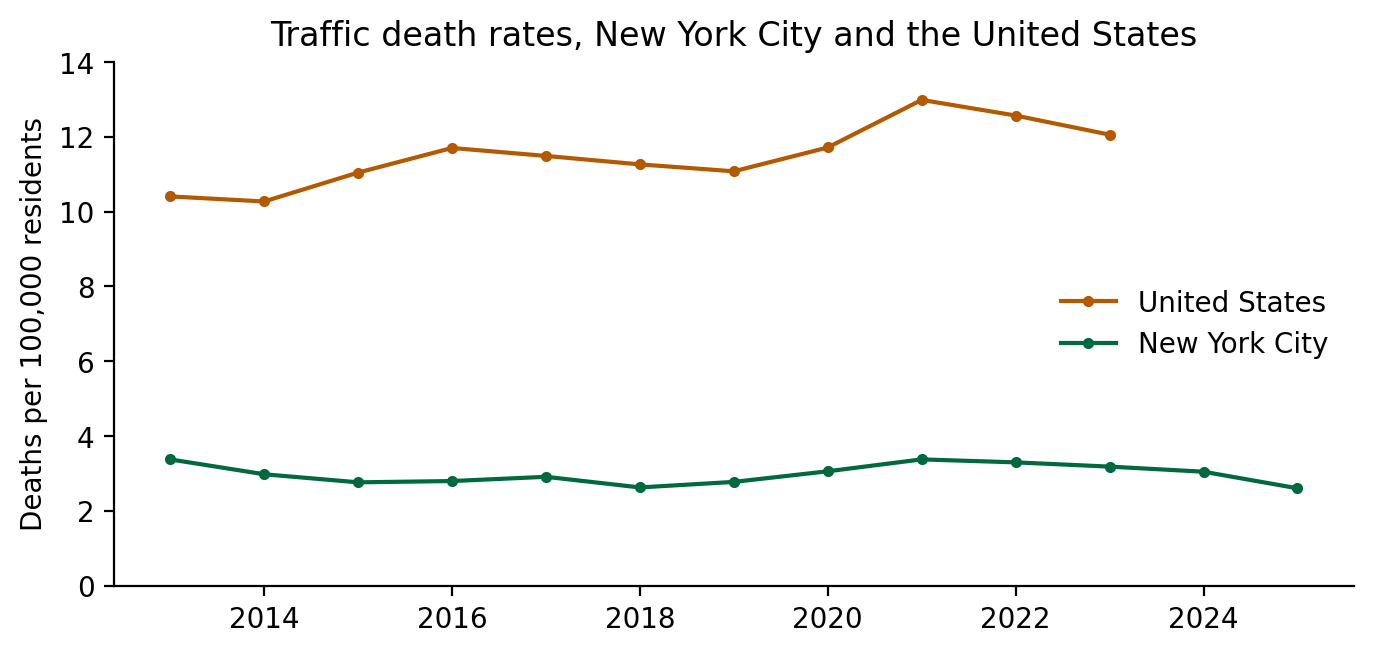

In [48]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(rates.index, rates['us_rate'], marker='o', ms=3, color='#b35900',
        label='United States')
ax.plot(rates.index, rates['nyc_rate'], marker='o', ms=3, color='#00693e',
        label='New York City')
ax.set(ylim=(0, 14), ylabel='Deaths per 100,000 residents',
       title='Traffic death rates, New York City and the United States')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False);

- From 2013 to 2021, the US rate rose from 10.40 to **12.99** per 100,000,
  by 25 percent.
- New York's rate fell to 2.62 in 2018 and was back at 3.37 in 2021, its 2013
  level.
- New York's rate is about a third of the nation's in 2013 and about a quarter
  in 2021. The gap widened because the national rate rose.

## What we found

- New York City's traffic death rate held steady from 2013 to 2021 while the
  nation's rose by a quarter. Relative to the nation, the city's rate fell.
- Half of the people killed in New York were pedestrians, with a median age
  of 58.

- What these data cannot show:
  - New York's rate uses the 2020 Census population for every year, so it
    ignores population change from year to year.
  - The city's numbers come from police reports; the nation's, from a page
    that compiles other sources. The two may count deaths differently.
  - A dense city with a subway differs from the nation in how people travel,
    and its trend can differ for many reasons. The comparison describes the
    gap. It does not show that the city's 2014 changes caused it.

### SQL and pandas

| SQL | pandas |
|---|---|
| `SELECT a, b FROM t` | `t[['a', 'b']]` |
| `WHERE x > 0` | `t.loc[t['x'] > 0]` |
| `SELECT DISTINCT a` | `t['a'].drop_duplicates()` |
| `GROUP BY g` with `COUNT(*)` | `t.groupby('g').size()` |
| `COUNT(col)` | `t.groupby('g')['col'].count()` |
| `COUNT(DISTINCT col)` | `t['col'].nunique()` |
| `HAVING COUNT(*) >= 25` | a filter after `groupby` |
| `ORDER BY n DESC LIMIT 5` | `.sort_values('n', ascending=False).head(5)` |
| `LEFT JOIN u USING (k)` | `t.merge(u, on='k', how='left')` |
| `CASE WHEN ... END` | `.map(...)` or a condition with `.loc` |
| `CAST(x AS INTEGER)` | `.astype(int)` |

- Use SQL to filter, join, and summarize where the data live; use pandas on
  the smaller result for figures and models.
- With a database server, its Python package gives you a connection, and
  `pd.read_sql(query, connection)` returns the result as a DataFrame.

## Activity notebook: which vehicles appear in crashes that kill pedestrians?

- **New question:** in single-vehicle crashes that killed a pedestrian, what
  kind of vehicle was involved, and has the mix changed?
- **New row unit:** one vehicle in a fatal crash, joined to one pedestrian.
- **What stays the same:** `GROUP BY`, `HAVING`, `CASE`, `WITH`, and joins on
  `collision_id`.
- **What changes:** `vehicle_type` is typed by hand in dozens of spellings, so
  `CASE` must group them before any count means something.
- Open `lec10_activity.ipynb`.

## Summary

| Goal | Write |
|---|---|
| Open a database in memory | `con = duckdb.connect()` |
| Open or create a database file | `con = duckdb.connect('file.duckdb')` |
| Read a DataFrame with SQL | `SELECT ... FROM df_name` |
| Run a query, get a DataFrame | `con.sql('SELECT ...').df()` |
| Change the database | `con.execute('CREATE OR REPLACE TABLE t AS SELECT ...')` |
| List columns and types | `DESCRIBE t` |
| Read files | `read_csv_auto('...')`, `read_json_auto('...*.json')` |
| Change a type | `CAST(x AS INTEGER)`, `CAST(d AS DATE)` |
| Keep rows | `WHERE a = 'x' AND b > 0`, `IN (...)`, `LIKE 'Q%'`, `ILIKE 'q%'` |
| Drop repeated rows | `SELECT DISTINCT a` |
| Missing values | `IS NULL`, `IS NOT NULL`, `COUNT(col)` |
| Summaries per group | `GROUP BY g` with `COUNT(*)`, `SUM`, `AVG`, `MEDIAN` |
| Count different values | `COUNT(DISTINCT col)` |
| Keep groups | `HAVING COUNT(*) >= 25` |
| Sort and cut | `ORDER BY n DESC LIMIT 5` |
| A column from conditions | `CASE WHEN ... THEN ... ELSE ... END` |
| Name a step | `WITH step AS (SELECT ...) SELECT ... FROM step` |
| Join on a key | `FROM a LEFT JOIN b ON a.k = b.k`, `JOIN b USING (k)` |
| Close the connection | `con.close()` |

In [49]:
con.close()   # release the file so that other programs can open it